# Plot showing damage functions with regression uncertainty

In [1]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import string
import zarr
import warnings
from tqdm.notebook import tqdm

import matplotlib as mpl
from matplotlib import pyplot as plt

from funcs_support import get_filepaths,get_params,utility_save,utility_print
from funcs_readregs import coeffs_mortality, coeffs_gdppc, coeffs_payroll
from funcs_plot import plot_dmgfs

dir_list = get_params()

extra_fonts = {'lato':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Regular.ttf'),
 'lato-bold':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Bold.ttf')}

subplot_lettering = string.ascii_uppercase #string.ascii_lowercase

In [2]:
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','popwght':True},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','popwght':True},
               'payroll':{'varname':'days90plus','geo_typ':'adm2-us','popwght':True}}

nsamples = 1000
rng = np.random.default_rng()

In [3]:
def get_coeff_draws(proc,load_kwargs = {},
                    rng = rng,
                    nsamples = nsamples):
    ''' Get MC draws of coefficients

    Parameters
    ---------------
    proc : str
        Name of impact variable

    load_kwargs : dict
        Piped into `coeffs_*()`

    rng : numpy random generator

    nsamples : int
        Number of MC samples of VCV to use

    Returns
    ---------------
    coeffs_mvn : xr.DataArray
    '''

    # Load regression coefficients
    if proc == 'gdppc':
        coeffs,vcv = coeffs_gdppc(**load_kwargs)
    elif proc == 'mortality':
        coeffs,vcv = coeffs_mortality(**load_kwargs)
    elif proc == 'payroll':
        coeffs,vcv = coeffs_payroll(**load_kwargs)
    else:
        raise KeyError()

    coeffs = coeffs.dropna('proj_base',how='all')
    if 'proj_base_1' in vcv:
        vcv.dropna('proj_base_1').dropna('proj_base_2')
    else:
        vcv = vcv.dropna('proj_base',how='all')

    # Get MC samples of coefficients
    if 'proj_base_1' in vcv:
        # If jointly estimated across parameters
        coeffs_tmp = coeffs.coeffs.stack(predproj = ['pred','proj_base'])
        vcv_tmp = vcv.vcv.stack(predproj_1 = ['pred_1','proj_base_1'],
                                 predproj_2 = ['pred_2','proj_base_2'])
        
        coeffs_mvn = rng.multivariate_normal(coeffs_tmp,
                                             vcv_tmp,
                                             size=nsamples)
        
        coeffs_mvn = xr.DataArray(coeffs_mvn,
                                  dims = ['sidx','predproj'],
                                  coords = {'predproj':coeffs_tmp.predproj})
        coeffs_mvn = coeffs_mvn.unstack('predproj')
    else:
        # If separate fit for each proj_base
        coeffs_mvn = xr.apply_ufunc(rng.multivariate_normal,
                                   coeffs.coeffs,
                                   vcv.vcv,
                                   input_core_dims = [['pred'],['pred_1','pred_2']],
                                   output_core_dims = [['sidx','pred']],
                                   kwargs = {'size':nsamples},
                                           dask = 'parallelized',
                                           dask_gufunc_kwargs = {'output_sizes':{'sidx':nsamples}},
                                   vectorize=True)
    return coeffs_mvn

In [4]:
def load_dmgfs(proc,load_kwargs = {},
              rng = rng,
              nsamples = nsamples):
    ''' Load MC'ed damage function, sampled at temperatures Tref

    Parameters
    ---------------
    proc : str
        Name of impact variable

    load_kwargs : dict
        Piped into `coeffs_*()`

    rng : numpy random generator

    nsamples : int
        Number of MC samples of VCV to use

    Returns
    ---------------
    dmgf : xr.DataArray
        `Tref` x `proj_base` x `sidx` datarray giving 
        coefficients at temperatures `Tref`


    '''
    
    # Load regression coefficients
    if proc == 'gdppc':
        coeffs,vcv = coeffs_gdppc(**load_kwargs)
    elif proc == 'mortality':
        coeffs,vcv = coeffs_mortality(**load_kwargs)
    elif proc == 'payroll':
        coeffs,vcv = coeffs_payroll(**load_kwargs)
    else:
        raise KeyError()

    coeffs = coeffs.dropna('proj_base',how='all')
    if 'proj_base_1' in vcv:
        vcv.dropna('proj_base_1').dropna('proj_base_2')
    else:
        vcv = vcv.dropna('proj_base',how='all')

    # Get MC samples of coefficients
    if 'proj_base_1' in vcv:
        # If jointly estimated across parameters
        coeffs_tmp = coeffs.coeffs.stack(predproj = ['pred','proj_base'])
        vcv_tmp = vcv.vcv.stack(predproj_1 = ['pred_1','proj_base_1'],
                                 predproj_2 = ['pred_2','proj_base_2'])
        
        coeffs_mvn = rng.multivariate_normal(coeffs_tmp,
                                             vcv_tmp,
                                             size=nsamples)
        
        coeffs_mvn = xr.DataArray(coeffs_mvn,
                                  dims = ['sidx','predproj'],
                                  coords = {'predproj':coeffs_tmp.predproj})
        coeffs_mvn = coeffs_mvn.unstack('predproj')
    else:
        # If separate fit for each proj_base
        coeffs_mvn = xr.apply_ufunc(rng.multivariate_normal,
                                   coeffs.coeffs,
                                   vcv.vcv,
                                   input_core_dims = [['pred'],['pred_1','pred_2']],
                                   output_core_dims = [['sidx','pred']],
                                   kwargs = {'size':nsamples},
                                           dask = 'parallelized',
                                           dask_gufunc_kwargs = {'output_sizes':{'sidx':nsamples}},
                                   vectorize=True)

    if np.any(['sumpoly' in k for k in coeffs_mvn.pred.values]):
        ts = np.arange(-20,51)
        var_stem = 'tassumpoly_'
        poly_degs = [int(re.split(var_stem,v)[-1]) for v in coeffs_mvn.pred.values if var_stem in v]
        t_vals = xr.DataArray(np.vstack([ts**k for k in poly_degs]),
                     dims = ['pred','bin_c'],
                     coords = {'pred':[v for v in coeffs_mvn.pred.values if var_stem in v],
                               'bin_c':ts})
    
        # Get damage function
        dmgf = (coeffs_mvn*t_vals).sum('pred')
        
        if proc == 'mortality':
            # Normalize over lowest value
            dmgf = dmgf - dmgf.sel(bin_c = slice(10,30)).min('bin_c')
        elif proc == 'gdppc':
            # Normalize over highest value
            dmgf = dmgf - dmgf.sel(bin_c = slice(10,30)).max('bin_c')
            #dmgf = dmgf - dmgf.sel(bin_c = 13)
        
        dmgf = dmgf.rename({'bin_c':'Tref'})
    elif 'bin' in coeffs_mvn.pred.values[0]:
        # Constructing the single-bin version
        dmgf = xr.apply_ufunc(rng.normal,
                   coeffs.isel(pred=0),
                   vcv.vcv.isel(pred_1 = 0,pred_2 = 0),
                   output_core_dims = [['sidx']],
                   vectorize=True,
                   kwargs = {'size':nsamples})
        
        dmgf = dmgf.expand_dims({'bin_f':np.arange(float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1]),
                                             125,5)})
        
        dmgf = xr.concat([xr.zeros_like(dmgf.isel(bin_f=0,drop=True)).expand_dims({'bin_f':np.arange(float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1])-20,
                                                                                   float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1]),
                                                                                   5)}),
                          dmgf],
                         dim='bin_f')
    
        dmgf = dmgf.rename({'bin_f':'Tref'}).coeffs
    elif 'days' in coeffs_mvn.pred.values[0]:
        dmgf = coeffs_mvn.expand_dims({'bin_f':np.arange(92.5, 125,5)}).isel(pred=0)
        dmgf = xr.concat([xr.zeros_like(dmgf.isel(bin_f=0,drop=True)).expand_dims({'bin_f':np.arange(92.5-20,
                                                                                           92.5,
                                                                                           5)}),
                                  dmgf],
                                 dim='bin_f')
        dmgf = dmgf.rename({'bin_f':'Tref'})

    return dmgf

In [5]:
colors = {'ERA5':'tab:red','JRA-3Q':'tab:orange','MERRA2':'tab:green','GMFD':'tab:blue','PRISM':'yellow','UDel':'yellow'}

proc_names = {'mortality':'mortality rate [/100,000]',
              'gdppc':'log GDP per capita growth',
              'payroll':'payroll fraction'}
proc_titles = {'mortality':'annual mortality rate',
               'gdppc':'GDP per capita growth',
               'payroll':'annual payroll'}
proc_xlims = {'mortality':[-15,45],
              'gdppc':[-2.5,32.5],
              'payroll':[70,115]}
proc_ylims = {'mortality':[-1,8],
              'gdppc':[-0.375,0.025],
              'payroll':[-0.00075,0.0001]}

## Reference with just the dmgfs

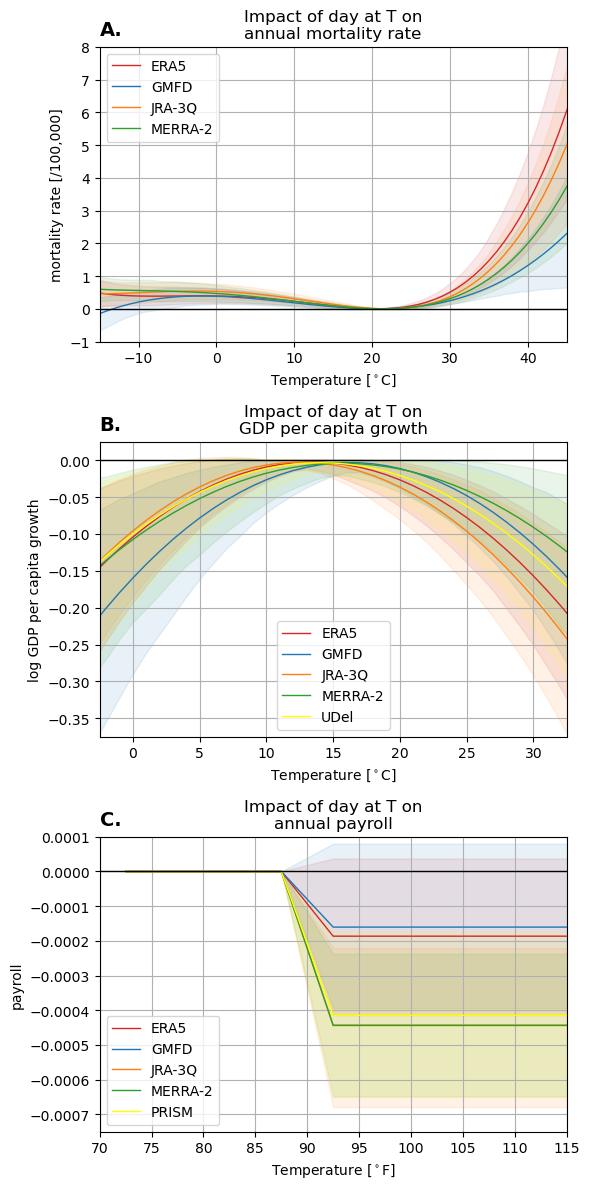

In [6]:
save_fig = False
output_fn = dir_list['figs']+'extra_figs/dmgfs'

fig = plt.figure(figsize=(6,12))
proclist = ['mortality','gdppc','payroll']

for plt_idx,proc in enumerate(proclist):
    dmgf = load_dmgfs(proc)

    ax = plt.subplot(len(proclist),1,plt_idx+1)

    ax = plot_dmgfs(dmgf,proc,ax=ax)

    ax.annotate(subplot_lettering[plt_idx]+'.',(0,1.025),xycoords = 'axes fraction',
                va = 'bottom',fontweight='bold',fontsize=14)

    ax.legend()

    if proc in ['mortality','gdppc']:
        ax.set_xlabel(r'Temperature [$^\circ$C]')
    elif proc in ['payroll']:
        ax.set_xlabel(r'Temperature [$^\circ$F]')

plt.tight_layout()

if save_fig:
    utility_print(output_fn)

## Version comparing different proc-specific configurations

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/dmgfs_byspecification.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/dmgfs_byspecification.png saved!


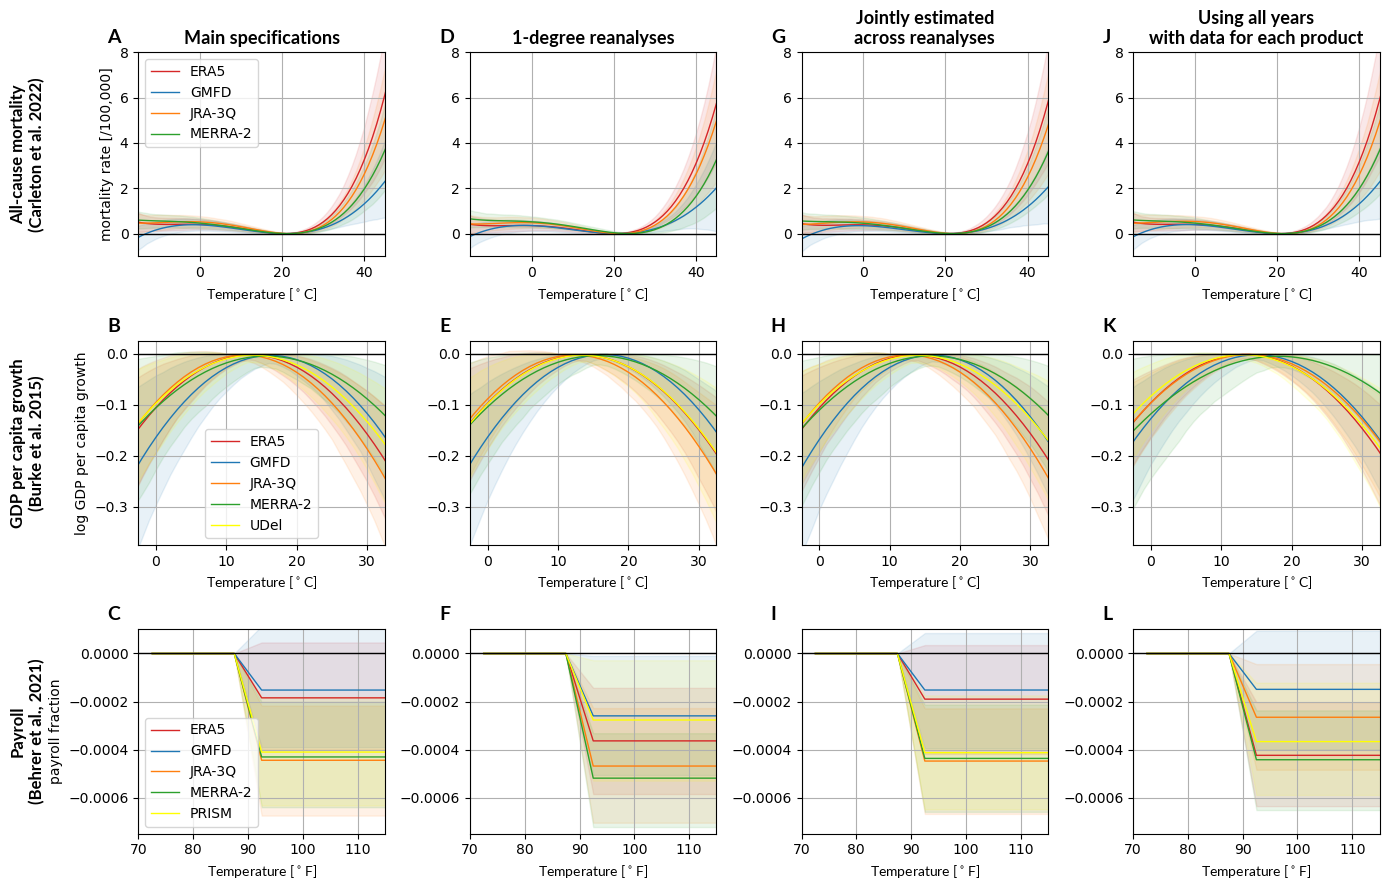

In [7]:
save_fig = True
output_fn = f'{dir_list['figs']}extra_figs/dmgfs_byspecification'

fig = plt.figure(figsize=(14,9))

proclist = ['mortality','gdppc','payroll']

coldicts = [{'resolution':'025deg'},
            {'resolution':'1deg'},
            {'obstreat':'joint','joint_':True},
            {'timeframe':'ALLYEARS'}]
            #{'mortality':{'indflag':'wInd'}}]
collabels = ['Main specifications',
             '1-degree reanalyses',
             'Jointly estimated\nacross reanalyses',
             'Using all years\nwith data for each product']
             #{'mortality':'with Indian data'}]

proc_full_names = {'mortality':'All-cause mortality\n(Carleton et al. 2022)',
                           'gdppc':'GDP per capita growth\n(Burke et al. 2015)',
                           'payroll':'Payroll\n(Behrer et al., 2021)'}
             
plt_idx = 0
for col_idx,colparams in enumerate(coldicts):
    for row_idx,proc in enumerate(proclist):
        if np.any([k in colparams for k in proclist]):
            if proc in colparams:
                dmgf = load_dmgfs(proc,load_kwargs = colparams[proc])
            else:
                continue
        else:
            dmgf = load_dmgfs(proc,load_kwargs = colparams)
            
        ax = plt.subplot(len(proclist),len(coldicts),(row_idx*len(coldicts))+1+col_idx)
    
        ax = plot_dmgfs(dmgf,proc,ax=ax,proc_names=proc_names)
    
        ax.annotate(subplot_lettering[plt_idx],(-0.125,1.03),xycoords = 'axes fraction',
                    va = 'bottom',font=extra_fonts['lato-bold'],fontsize=14)
        plt_idx += 1

        if col_idx == 0:
            ax.legend()
    
        if proc in ['mortality','gdppc']:
            ax.set_xlabel(r'Temperature [$^\circ$C]',font=extra_fonts['lato'])
        elif proc in ['payroll']:
            ax.set_xlabel(r'Temperature [$^\circ$F]',font=extra_fonts['lato'])

        if col_idx > 0:
            ax.set_ylabel('')
        if col_idx == 0:
            ann = ax.annotate(proc_full_names[proc],
                                (-0.45,0.5),
                                xycoords = 'axes fraction',
                                rotation=90,
                                ha='center',va='center',
                               font=extra_fonts['lato-bold'],
                               fontsize=12)

        if proc in collabels[col_idx]:
            ax.annotate(collabels[col_idx][proc],
                        (0.025,0.975),xycoords = 'axes fraction',
                        ha='left',va='top',bbox={'boxstyle':'round,pad=0.4','fc':'white','ec':'grey'},
                        font=extra_fonts['lato'])
            ax.set_title('')
        else:
            if row_idx == 0:
                ax.set_title(collabels[col_idx],font=extra_fonts['lato-bold'],fontsize=13)
            else:
                ax.set_title('')
            
                        
    
    plt.tight_layout()

if save_fig:
    utility_print(output_fn)

## Version showing impact of using different precipitation datasets

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/dmgfs_by_crossprs.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/dmgfs_by_crossprs.png saved!


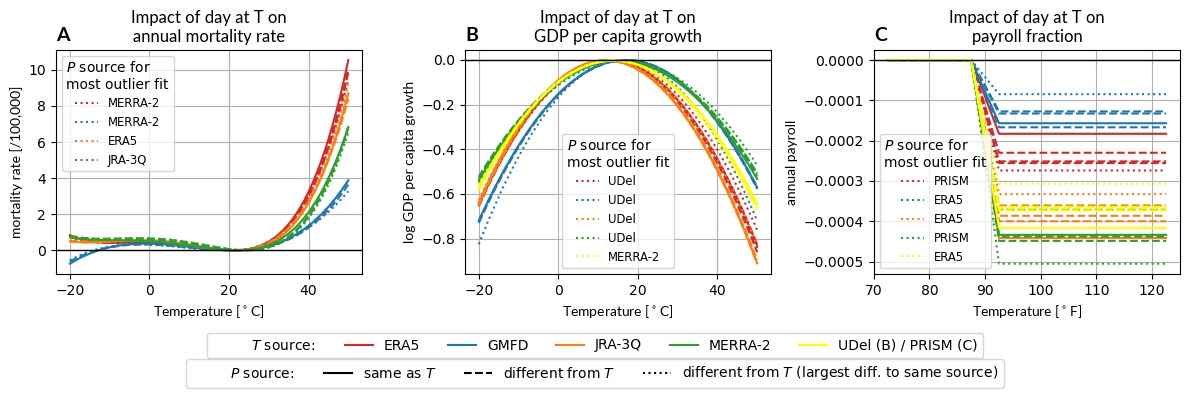

In [11]:
save_fig = True
output_fn = dir_list['figs']+'extra_figs/dmgfs_by_crossprs'

colors = {'ERA5':'tab:red','JRA-3Q':'tab:orange','MERRA2':'tab:green','GMFD':'tab:blue','PRISM':'yellow','UDel':'yellow'}
linestyles = {'ERA5':'--','JRA-3Q':':','MERRA2':'-.','GMFD':'--','UDel':'-.','PRISM':'-.'}

# (payroll doesn't use precipitation)
proclist = ['mortality','gdppc','payroll']
proc_names = {'mortality':'mortality rate [/100,000]',
              'gdppc':'log GDP per capita growth',
              'payroll':'annual payroll'}
proc_titles = {'mortality':'annual mortality rate',
               'gdppc':'GDP per capita growth',
               'payroll':'payroll fraction'}



fig = plt.figure(figsize=(12,4))
gridspec = plt.GridSpec(nrows=2,ncols=3,height_ratios = [1,0.2])
for plt_idx,proc in enumerate(proclist):
    ax = fig.add_subplot(gridspec[0,plt_idx])
    dmgf = load_dmgfs(proc,load_kwargs = {'get_crossprs':True})
    # Just show central estimates
    dmgf = dmgf.mean('sidx')

    # Get mean MAD vs. other proj_base_prs for each one to find the outlier 
    #diffs = (np.abs(dmgf - dmgf.rename({'proj_base_pr':'proj_base_pr2'})).
    #         mean([d for d in dmgf.sizes if 'proj_base' not in d]).mean('proj_base_pr2'))

    diffs = np.abs(dmgf - dmgf.where(dmgf.proj_base == dmgf.proj_base_pr).mean('proj_base_pr')).mean('Tref')

    outlier_precips = diffs['proj_base_pr'][diffs.argmax('proj_base_pr')]

    outlier_prs = []
    for pb in dmgf.proj_base.values:
        outlier_pr = outlier_precips.sel(proj_base=pb).values
        outlier_prs.append(outlier_pr)
        for pbp in dmgf.proj_base_pr.values:
            if pbp == pb:
                linestyle = '-'
            elif pbp == outlier_pr:
                linestyle=':'
            else:
                linestyle = '--'
            
            dmgf.sel(proj_base=pb,proj_base_pr=pbp).plot(color=colors[pb],
                                                         linestyle=linestyle)

    ax.annotate(subplot_lettering[plt_idx],(0,1.025),xycoords = 'axes fraction',
                va = 'bottom',fontweight='bold',fontsize=14,font=extra_fonts['lato-bold'])
    ax.legend([mpl.lines.Line2D([0],[0],color=colors[pb],linestyle=':') for pb in dmgf.proj_base.values],
             [re.sub('MERRA2','MERRA-2',str(k)) for k in outlier_prs],
              title=r'$P$ source for'+'\nmost outlier fit',
              fontsize='small')

    if proc in ['mortality','gdppc']:
            ax.set_xlabel(r'Temperature [$^\circ$C]',font=extra_fonts['lato'])
    elif proc in ['payroll']:
        ax.set_xlabel(r'Temperature [$^\circ$F]',font=extra_fonts['lato'])
    ax.set_ylabel(proc_names[proc],font=extra_fonts['lato'])
    ax.set_title('Impact of day at T on\n'+proc_titles[proc],font=extra_fonts['lato'],fontsize=12)

    ax.axhline(0,color='k',linewidth=1)
    plt.grid()


lgd = fig.legend([mpl.patches.Rectangle((0,0), 1, 1, fill=False, ec='none',
                                 visible=False),
                  *[mpl.lines.Line2D([0],[0],color=col,linestyle='-') 
                    for col in ['tab:red','tab:blue','tab:orange','tab:green','yellow']
                       ]],
          [r'$T$ source: ','ERA5','GMFD','JRA-3Q','MERRA-2','UDel (B) / PRISM (C)'],
          bbox_to_anchor = (0.5,0.075),loc='lower center', ncol=6, 
                )

fig.legend([mpl.patches.Rectangle((0,0), 1, 1, fill=False, ec='none',
                                 visible=False),
            *[mpl.lines.Line2D([0],[0],color='k',linestyle=styl) for styl in ['-','--',':']]],
            [r'$P$ source: ',
             r'same as $T$',
           r'different from $T$',
           r'different from $T$ (largest diff. to same source)'],
           bbox_to_anchor = (0.5,0.0),loc = 'lower center',title='',ncol=4)

plt.tight_layout()

if save_fig:
    utility_print(output_fn)

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/dmgfs_allprods.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/dmgfs_allprods.png saved!


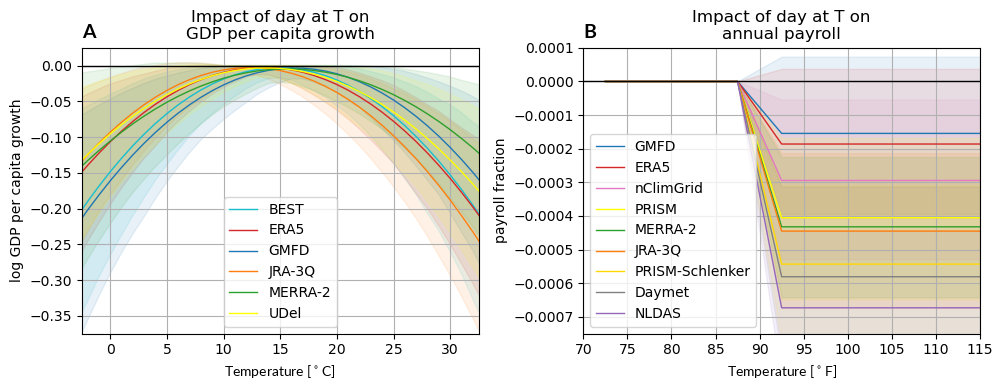

In [13]:
save_fig = True
output_fn = dir_list['figs']+'extra_figs/dmgfs_allprods'

all_colors = {'ERA5':'tab:red','GMFD':'tab:blue','JRA-3Q':'tab:orange','MERRA2':'tab:green',
              'UDel':'yellow','BEST':'tab:cyan','Daymet':'grey','NLDAS':'tab:purple',
              'PRISM':'yellow','PRISM-Schlenker':'gold','nClimGrid':'tab:pink'}
proc_names = {'mortality':'mortality rate [/100,000]',
              'gdppc':'log GDP per capita growth',
              'payroll':'payroll fraction'}


fig = plt.figure(figsize=(10,4))
proclist = ['gdppc','payroll']

for plt_idx,proc in enumerate(proclist):
    dmgf = load_dmgfs(proc)

    if proc == 'payroll':
        dmgf['proj_base'] = [re.sub(r'nClim\-Grid','nClimGrid',pb) for pb in dmgf['proj_base'].values]
        # List products in legend in order of impact for ease of reading
        dmgf = dmgf.sel(proj_base=['GMFD','ERA5','nClimGrid','PRISM','MERRA2','JRA-3Q','PRISM-Schlenker','Daymet','NLDAS'])

    ax = plt.subplot(1,len(proclist),plt_idx+1)

    ax = plot_dmgfs(dmgf,proc,ax=ax,proc_names=proc_names,
                    colors = all_colors)

    ax.annotate(subplot_lettering[plt_idx],(0,1.025),xycoords = 'axes fraction',
                va = 'bottom',fontsize=14,font=extra_fonts['lato-bold'])

    ax.legend()

    if proc in ['mortality','gdppc']:
        ax.set_xlabel(r'Temperature [$^\circ$C]',font=extra_fonts['lato'])
    elif proc in ['payroll']:
        ax.set_xlabel(r'Temperature [$^\circ$F]',font=extra_fonts['lato'])

plt.tight_layout()

if save_fig:
    utility_print(output_fn)